# FIN pretrained on the 7 users' real + warped windows, with and without MotionSense, vs random-init

- **train:** WISDM users 12, 18, 19, 20, 31, 34, 36, **test:** the other 29; seeds 42, 0, 1, 2, 3
- **real + warped, frozen:** the FIN imitates spectral entropy, autocorrelation peak and spectral peak on single-axis windows of the 7 training users only: their real windows and 12,006 warped copies (random tempo 0.75-1.35x, randomly flipped around the mean and/or reversed in time, a little noise). Labels are not used. Then it stays fixed and only the head learns
- **MotionSense + real + warped, frozen:** the same plus all of MotionSense (24 other people, labels not used)
- **random-init, trainable:** same architecture, random weights
- **classifier:** FIN embedding of each axis -> Dense 128 -> softmax, no hand-made features
- the seed sets the warped windows, the FIN pretraining and the head training

In [1]:
import os
import sys
import warnings

os.environ["KERAS_BACKEND"] = "torch"
warnings.filterwarnings("ignore")
FIN = os.path.dirname(os.getcwd())
sys.path[:0] = [FIN, os.path.join(FIN, "FIN-classifiers"), os.path.join(FIN, "data-processing")]

import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from keras import layers, ops
from sklearn.metrics import f1_score

import config as cfg
import wisdm_windowing as ww
from augmentation import warped
import motionsense_windowing as ms
from bilin_fin_temporal_plus_original import RhythmFIN, targets

SEEDS = cfg.SEEDS
TRAIN_USERS = [12, 18, 19, 20, 31, 34, 36]
N_WARPED = 12006

## Data

In [2]:
windows, users, labels = ww.window_raw()
print(f"{len(windows)} windows, {len(np.unique(users))} users")

10367 windows, 36 users


In [3]:
tr = np.isin(users, TRAIN_USERS)
te = ~tr
real = windows[tr].reshape(-1, cfg.SEGMENT)  # every axis of every training window
motionsense = ms.window_raw()[0].reshape(-1, cfg.SEGMENT)
test_axes = windows[te].reshape(-1, cfg.SEGMENT)
true_targets = targets(test_axes)
print(f"test {te.sum()} windows of {36 - len(TRAIN_USERS)} users; {len(real)} real single-axis training windows, "
      f"{len(motionsense)} MotionSense ones")

test 7710 windows of 29 users; 7971 real single-axis training windows, 15579 MotionSense ones


## Model

In [4]:
class TestAccuracy(keras.callbacks.Callback):
    #Test accuracy after every epoch

    def __init__(self, x, y):
        super().__init__()
        self.x, self.y, self.curve = x, y, []

    def on_epoch_end(self, epoch, logs=None):
        rng = torch.random.get_rng_state()
        pred = self.model.predict(self.x, batch_size=1024, verbose=0).argmax(axis=1)
        torch.random.set_rng_state(rng)
        self.curve.append(float(np.mean(pred == self.y)))


class FINClassifier(keras.Model):

    def __init__(self, fin, **kw):
        super().__init__(**kw)
        self.fin = fin
        self.hidden = layers.Dense(cfg.HEAD_WIDTH, activation="relu")
        self.out = layers.Dense(cfg.N_CLASSES, activation="softmax")

    def call(self, x):
        h = ops.concatenate([self.fin.embed(x[:, i, :]) for i in range(len(cfg.AXES))], axis=1)
        return self.out(self.hidden(h))


def pretrain(axes, seed):
    keras.utils.set_random_seed(seed)
    fin = RhythmFIN()
    y = targets(axes)
    fin.compile(optimizer=keras.optimizers.Adam(cfg.FIN_LR), loss="mse")
    fin.fit(axes, ((y - y.mean(0)) / y.std(0)).astype(np.float32),
            epochs=cfg.FIN_EPOCHS, batch_size=cfg.BATCH_SIZE, verbose=0)
    return fin.get_weights()


def classify(tr, te, seed, weights, trainable):
    keras.utils.set_random_seed(seed)
    fin = RhythmFIN()
    if weights is not None:
        fin(np.zeros((1, cfg.SEGMENT), np.float32))
        fin.set_weights(weights)
    fin.trainable = trainable
    keras.utils.set_random_seed(seed)
    model = FINClassifier(fin)
    track = TestAccuracy(windows[te], labels[te])
    model.compile(optimizer=keras.optimizers.Adam(cfg.HEAD_LR), loss="sparse_categorical_crossentropy")
    model.fit(windows[tr], labels[tr], epochs=cfg.HEAD_EPOCHS, batch_size=cfg.BATCH_SIZE,
              verbose=0, callbacks=[track])
    pred = model.predict(windows[te], batch_size=1024, verbose=0).argmax(axis=1)
    return pred, track.curve

## Experiment

In [5]:
def imitation_r2(weights, pool):
    """RÂ² of the pretrained FIN on the unseen users' real windows, as in the synthetic-signals table."""
    y = targets(pool)
    fin = RhythmFIN()
    fin(np.zeros((1, cfg.SEGMENT), np.float32))
    fin.set_weights(weights)
    pred = fin.predict(test_axes, batch_size=4096, verbose=0) * y.std(0) + y.mean(0)
    return 1 - ((true_targets - pred) ** 2).sum(0) / ((true_targets - true_targets.mean(0)) ** 2).sum(0)


MODELS = ["real + warped, frozen", "MotionSense + real + warped, frozen", "random-init, trainable"]
COLORS = dict(zip(MODELS, ["#2a78d6", "#1baf7a", "#eb6834"]))
rows, r2_rows, curves = [], [], {m: [] for m in MODELS}
truth = labels[te]
for seed in SEEDS:
    rng = np.random.default_rng(seed)
    warp = np.stack([warped(rng, real) for _ in range(N_WARPED)]).astype(np.float32)
    pools = {"real + warped, frozen": np.concatenate([real, warp]),
             "MotionSense + real + warped, frozen": np.concatenate([motionsense, real, warp])}
    for model in MODELS:
        weights = None
        if model in pools:
            weights = pretrain(pools[model], seed)
            r2_rows.append({"seed": seed, "pretraining": model.removesuffix(", frozen"),
                            **dict(zip(["spectral entropy", "AC peak", "spectral peak"], imitation_r2(weights, pools[model])))})
        pred, curve = classify(tr, te, seed, weights, trainable=weights is None)
        curves[model].append(curve)
        rows.append({"seed": seed, "model": model, "accuracy": np.mean(pred == truth),
                     "macro F1": f1_score(truth, pred, average="macro"),
                     **{a: np.mean(pred[truth == i] == i) for i, a in enumerate(cfg.ACTIVITIES)}})
    print(f"seed {seed} done", flush=True)
results, r2 = pd.DataFrame(rows), pd.DataFrame(r2_rows)

seed 42 done


seed 0 done


seed 1 done


seed 2 done


seed 3 done


In [6]:
def mean_sd(df, by, cols, order):
    g = df.groupby(by)[cols]
    return (g.mean().round(4).astype(str) + " Â± " + g.std().round(4).astype(str)).loc[order]


pd.set_option("display.width", 200)
display(mean_sd(results, "model", ["accuracy", "macro F1"], MODELS),
        results.pivot(index="seed", columns="model", values="accuracy")[MODELS].round(4),
        results.groupby("model")[list(cfg.ACTIVITIES)].mean().loc[MODELS].round(3),
        mean_sd(r2, "pretraining", ["spectral entropy", "AC peak", "spectral peak"],
                [m.removesuffix(", frozen") for m in MODELS[:2]]))

,accuracy,macro F1
model,,
"real + warped, frozen",0.8291 Â± 0.0131,0.7148 Â± 0.0071
"MotionSense + real + warped, frozen",0.8273 Â± 0.0149,0.709 Â± 0.0135
"random-init, trainable",0.7993 Â± 0.0132,0.6935 Â± 0.0135


model,"real + warped, frozen","MotionSense + real + warped, frozen","random-init, trainable"
seed,,,
0,0.8243,0.8271,0.7820
1,0.8257,0.8125,0.8062
2,0.8388,0.8130,0.8134
3,0.8115,0.8377,0.7891
42,0.8450,0.8460,0.8058


,Jogging,Walking,Upstairs,Downstairs,Sitting,Standing
model,,,,,,
"real + warped, frozen",0.840,0.951,0.540,0.584,0.845,0.679
"MotionSense + real + warped, frozen",0.842,0.954,0.524,0.556,0.860,0.673
"random-init, trainable",0.842,0.860,0.557,0.672,0.779,0.723


,spectral entropy,AC peak,spectral peak
pretraining,,,
real + warped,0.9096 Â± 0.0078,0.9249 Â± 0.0042,0.8328 Â± 0.0097
MotionSense + real + warped,0.9342 Â± 0.005,0.9411 Â± 0.0017,0.8799 Â± 0.011


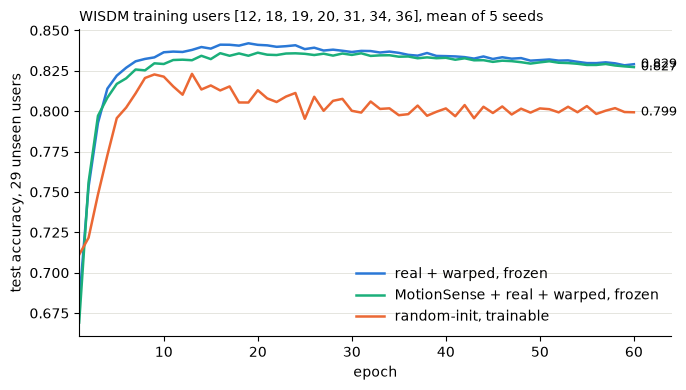

In [7]:
epochs = np.arange(1, cfg.HEAD_EPOCHS + 1)
fig, ax = plt.subplots(figsize=(7, 4))
for model, color in COLORS.items():
    mean = np.mean(curves[model], axis=0)
    ax.plot(epochs, mean, color=color, linewidth=1.8, label=model)
    ax.annotate(f"{mean[-1]:.3f}", (epochs[-1], mean[-1]), xytext=(5, 0), textcoords="offset points",
                va="center", fontsize=9)
ax.set_xlabel("epoch")
ax.set_ylabel(f"test accuracy, {36 - len(TRAIN_USERS)} unseen users")
ax.set_xlim(1, cfg.HEAD_EPOCHS + 4)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e1e0d9", linewidth=0.6)
ax.legend(frameon=False, loc="lower right")
ax.set_title(f"WISDM training users {TRAIN_USERS}, mean of {len(SEEDS)} seeds", fontsize=10, loc="left")
plt.tight_layout()
plt.show()